# Phase 6b part 2: outlier options and more model types

Phase 6b showed that loss functions, RFECV and tuning do not beat the Phase 6a random forest (r = 0.39 for a new taluka with the 3 km buffer). This notebook finishes the two roadmap items still open before deep learning:

| Step | Roadmap | Question |
|---|---|---|
| 2 | 6.2 | Does handling the outlier yields in training help: removing the Phase 1B strong outliers, winsorizing, or a log of yield? |
| 3 | 6.3 | Do other model types do better: Lasso, XGBoost, LightGBM, Gaussian process, median (quantile) regression? |
| 4 | | All experiments side by side, with paired tests against the random forest |

**Same test as Phase 6b:** the same 21 test folds (1 km groups, 3 repeats × 5 folds; leave one taluka out, 6 folds) and the same 3 km buffer. The 183 hold-out fields stay locked.

**Fair comparison (roadmap 1.8):** outlier options change only the **training** yields. Every test field is always scored with its real reported yield, so no option can look better by removing hard fields from the test.

## Step 0: Setup

Same data as Phase 6b, plus the Phase 1B outlier class of every field (clean, weak, strong; the 3 impossible yields were already removed in Phase 1B). Features: the Phase 6a choice (128).

**Found:** _(fill after running)_

In [1]:
from pathlib import Path
import os, sys, time, logging, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LassoCV, QuantileRegressor
from sklearn.model_selection import GroupKFold
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
warnings.filterwarnings("ignore"); logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

here = Path.cwd()
ROOT = here if (here / "data" / "raw").exists() else here.parent
sys.path.insert(0, str(ROOT / "src"))
from evaluation import evaluate, compare
OUT = ROOT / "results" / "phase6"; OUT.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "reports" / "figures" / "phase6"; FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
THREADS = int(os.environ.get("SLURM_CPUS_PER_TASK", -1))          # on the cluster: exactly the cores given to the job
SERIF = next((n for n in ["Times New Roman", "Liberation Serif", "DejaVu Serif"] if any(f.name == n for f in font_manager.fontManager.ttflist)), "serif")
plt.rcParams.update({"font.family": SERIF, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

f = gpd.read_file(ROOT / "data" / "processed_v2" / "yield_spatial_v2.gpkg").set_index("uid")
X = pd.read_csv(ROOT / "results" / "phase4" / "P4_features_clean.csv").set_index("uid")
dic = pd.read_csv(ROOT / "results" / "phase4" / "P4_feature_dictionary.csv").set_index("feature")
FOLDS = pd.read_csv(ROOT / "results" / "phase5" / "folds_v2.csv").set_index("uid")
YG = pd.read_csv(ROOT / "data" / "processed_v2" / "P1B_yield_group.csv").set_index("uid")["yield_group"]   # Phase 1B outlier class
dev = X.index[~X["holdout"]]                                     # 1,019 development fields; hold-out stays locked
Xd, yd = X.loc[dev].drop(columns="holdout"), f.loc[dev, "crop_yield"]
CAT = ["year", "ground_variety", "ground_irrigation", "ground_soil_color_group", "ground_soil_texture_group", "ground_soil_depth_group", "ground_soil_structure_group"]
for c in CAT:
    Xd[c] = Xd[c].astype(object).where(Xd[c].notna(), "missing").astype(str)
pts = f.loc[dev].geometry.representative_point()
XY = pd.DataFrame({"x": pts.x, "y": pts.y}, index=dev)
F = FOLDS.loc[dev, ["group_s1", "group_s2", "group_s3", "loto"]] # same 21 test folds as Phase 6b
BLOCK = FOLDS.loc[dev, "block"]                                  # 10 km blocks, for the inner folds (as in 6b)
BUF = 3000                                                       # metres, as in Phase 6b
S128 = pd.read_csv(OUT / "P6_chosen_features.csv")["feature"].tolist()     # the Phase 6a choice
GRP = YG.reindex(dev)
print(f"development fields: {len(dev)} | features: {len(S128)} | buffer: {BUF} m | threads: {THREADS} | font: {SERIF}")
print("Phase 1B classes among development fields:", GRP.value_counts().to_dict())

development fields: 1019 | features: 128 | buffer: 3000 m | threads: 32 | font: DejaVu Serif
Phase 1B classes among development fields: {'clean': 954, 'weak': 42, 'strong': 23}


## Step 1: Models and the outlier options

**Reference:** random forest, 128 features, default settings (as in 6a and 6b).

**Outlier options (roadmap 6.2), applied to the training yields of each fold only, with the reference random forest:**
- **Remove strong outliers:** leave out the fields that Phase 1B flagged as strong outliers (3 or more methods, including a robust one).
- **Winsorize at P1 and P99:** yields below the 1st or above the 99th percentile of the training fields are set to those values.
- **Winsorize at the IQR fences:** the same, at Q1 − 1.5 IQR and Q3 + 1.5 IQR (Tukey 1977).
- **Log of yield:** the model learns log(1 + yield); predictions are turned back with exp(p) − 1.

**More model types (roadmap 6.3), same 128 features, settings as close to CatBoost as possible (500 trees, learning rate 0.05):**
- **Lasso:** a straight-line model that sets weak features to zero; the penalty is chosen inside each training set (5 inner folds).
- **XGBoost** and **LightGBM:** boosted trees, like CatBoost.
- **LightGBM, median:** the same, trained for the median instead of the mean (quantile loss, roadmap 6.2).
- **Gaussian process:** predicts from the similarity between fields in feature space (RBF kernel plus a noise term, fitted inside each training set).
- **Quantile regression (median, linear):** a straight-line model for the median (Koenker and Bassett 1978). Its L1 penalty is chosen inside each training set from {0.001, 0.01, 0.1} with 3 inner folds of 10 km blocks; without a penalty, the quick test showed it overfits badly.

The reference random forest is run first.

**Found:** _(fill after running)_

In [2]:
# Step 1: models and the outlier options (all changes apply to the training fields only; every test field is always scored)
def prep(cols):
    cats = [c for c in CAT if c in cols]; nums = [c for c in cols if c not in cats]
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5), cats),
                              ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), nums)])
def rf():    return make_pipeline(prep(S128), RandomForestRegressor(n_estimators=500, min_samples_leaf=5, max_features=0.33, n_jobs=THREADS, random_state=SEED))
def lasso(): return make_pipeline(prep(S128), LassoCV(cv=5, alphas=50, max_iter=20000, n_jobs=THREADS, random_state=SEED))
def xgb():   return make_pipeline(prep(S128), XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, tree_method="hist", n_jobs=THREADS, random_state=SEED, verbosity=0))
def lgbm(objective="regression", **kw):
    return make_pipeline(prep(S128), LGBMRegressor(n_estimators=500, learning_rate=0.05, objective=objective, n_jobs=THREADS, random_state=SEED, verbose=-1, **kw))
def gp():
    k = ConstantKernel(1.0) * RBF(length_scale=10.0) + WhiteKernel(noise_level=1.0)
    return make_pipeline(prep(S128), GaussianProcessRegressor(kernel=k, normalize_y=True, random_state=SEED))
class QRegCV:
    """Linear median regression with an L1 penalty chosen inside the training fields (3 inner folds of 10 km blocks, as in 6b).
    Without a penalty, about 150 inputs on 650 to 850 fields overfit badly."""
    GRID = [0.001, 0.01, 0.1]
    def fit(self, X, y):
        inner = list(GroupKFold(n_splits=3).split(X, groups=BLOCK.loc[X.index].values)); sc = []
        for a in self.GRID:
            mk = lambda: make_pipeline(prep(S128), QuantileRegressor(quantile=0.5, alpha=a, solver="highs"))
            sc.append(np.mean([np.mean(np.abs(y.iloc[va] - mk().fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[va]))) for tr, va in inner]))
        self.alpha = self.GRID[int(np.argmin(sc))]; QR_CHOICES.append(self.alpha)
        self.m = make_pipeline(prep(S128), QuantileRegressor(quantile=0.5, alpha=self.alpha, solver="highs")).fit(X, y); return self
    def predict(self, X): return self.m.predict(X)
QR_CHOICES = []

class Handle:
    """Outlier option wrapped around a model. Only the training yields are changed; predictions are on the normal scale."""
    def __init__(self, make, mode): self.make, self.mode = make, mode
    def fit(self, X, y):
        y = y.astype(float).copy(); keep = np.ones(len(y), bool)
        if self.mode == "drop_strong":
            keep = (GRP.reindex(X.index) != "strong").to_numpy()
        elif self.mode == "winsor_p1_p99":
            lo, hi = np.percentile(y, [1, 99]); y = y.clip(lo, hi)
        elif self.mode == "winsor_iqr":
            q1, q3 = np.percentile(y, [25, 75]); y = y.clip(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))
        elif self.mode == "log":
            y = np.log1p(y)
        self.m = self.make().fit(X[keep], y[keep]); return self
    def predict(self, X):
        p = np.asarray(self.m.predict(X), float)
        return np.expm1(p) if self.mode == "log" else p

RES = {}
def run(name, factory, buffer=BUF):
    t = time.time(); pf, sm, oof = evaluate(factory, Xd[S128], yd, F, schemes=["group", "loto"], xy=XY, buffer_m=buffer)
    RES[name] = (pf, sm, oof); s = sm.set_index("scheme")
    print(f"  {name:42s} | {time.time() - t:5.0f} s | group r = {s.at['group', 'r_mean']:.3f} | new taluka r = {s.at['loto', 'r_mean']:.3f} | "
          f"MAE {s.at['group', 'MAE_q_acre_mean']:.2f} / {s.at['loto', 'MAE_q_acre_mean']:.2f}")
run("Random forest (reference, as in 6b)", rf)

  Random forest (reference, as in 6b)        |    13 s | group r = 0.473 | new taluka r = 0.391 | MAE 1.80 / 1.84


## Step 2: Outlier options (roadmap 6.2)

Each option against the reference. The roadmap picks the option by MAE and by the error on the lowest and highest 10% of yields (Step 4).

**Found:** _(fill after running)_

In [3]:
# Step 2: outlier handling (roadmap 6.2), all with the reference random forest
run("Remove strong outliers (training only)", lambda: Handle(rf, "drop_strong"))
run("Winsorize at P1 and P99", lambda: Handle(rf, "winsor_p1_p99"))
run("Winsorize at the IQR fences", lambda: Handle(rf, "winsor_iqr"))
run("Log of yield", lambda: Handle(rf, "log"))
pf = RES["Remove strong outliers (training only)"][0]
print("\nstrong outliers among development fields:", int((GRP == "strong").sum()), "| weak:", int((GRP == "weak").sum()))

  Remove strong outliers (training only)     |    12 s | group r = 0.385 | new taluka r = 0.371 | MAE 1.83 / 1.84


  Winsorize at P1 and P99                    |    13 s | group r = 0.448 | new taluka r = 0.376 | MAE 1.81 / 1.83


  Winsorize at the IQR fences                |    12 s | group r = 0.423 | new taluka r = 0.372 | MAE 1.83 / 1.84


  Log of yield                               |    13 s | group r = 0.460 | new taluka r = 0.387 | MAE 1.82 / 1.83

strong outliers among development fields: 23 | weak: 42


## Step 3: More model types (roadmap 6.3)

**Found:** _(fill after running)_

In [4]:
# Step 3: more model types (roadmap 6.3); LightGBM median = quantile loss (roadmap 6.2)
run("Lasso", lasso)
run("XGBoost", xgb)
run("LightGBM", lgbm)
run("LightGBM, median (quantile loss)", lambda: lgbm("quantile", alpha=0.5))
run("Gaussian process", gp)
run("Quantile regression (median, linear)", QRegCV)
print("\nL1 penalty chosen for the linear median regression (21 outer folds):", pd.Series(QR_CHOICES).value_counts().sort_index().to_dict())

  Lasso                                      |    25 s | group r = 0.418 | new taluka r = 0.352 | MAE 1.92 / 1.89


  XGBoost                                    |    35 s | group r = 0.450 | new taluka r = 0.351 | MAE 1.90 / 1.98


  LightGBM                                   |    54 s | group r = 0.388 | new taluka r = 0.389 | MAE 2.10 / 2.01


  LightGBM, median (quantile loss)           |    46 s | group r = 0.395 | new taluka r = 0.378 | MAE 1.86 / 1.85


  Gaussian process                           |    21 s | group r = 0.415 | new taluka r = 0.338 | MAE 1.88 / 1.87


  Quantile regression (median, linear)       |    42 s | group r = 0.400 | new taluka r = 0.388 | MAE 1.92 / 1.90

L1 penalty chosen for the linear median regression (21 outer folds): {0.01: 19, 0.1: 2}


## Step 4: All experiments together

r, RMSE, MAE and the MAE on the lowest and highest 10% of yields, for every experiment. Paired tests against the reference (corrected resampled t-test, Nadeau and Bengio 2003): positive gain = better than the random forest.

**Found:** _(fill after running)_

In [5]:
# Step 4: all experiments side by side, and paired tests against the reference random forest (same folds, same buffer)
cols = {"r_mean": "r", "RMSE_q_acre_mean": "RMSE", "MAE_q_acre_mean": "MAE", "MAE_low10_q_acre_mean": "MAE lowest 10%", "MAE_high10_q_acre_mean": "MAE highest 10%"}
rows = []
for k, (pf, sm, _) in RES.items():
    s = sm.set_index("scheme")
    row = {"experiment": k}
    for sch, lab in [("group", "1 km groups"), ("loto", "new taluka")]:
        for c, n in cols.items():
            row[f"{lab} {n}"] = s.at[sch, c]
    rows.append(row)
EXP = pd.DataFrame(rows); EXP.to_csv(OUT / "P6b2_experiments.csv", index=False)
show = ["experiment", "1 km groups r", "new taluka r", "new taluka RMSE", "new taluka MAE", "new taluka MAE lowest 10%", "new taluka MAE highest 10%"]
print(EXP[show].round(3).to_string(index=False))
REF = RES["Random forest (reference, as in 6b)"][0]; rows = []
for k, (pf, _, _) in RES.items():
    if k.startswith("Random forest (reference"): continue
    for scheme in ["group", "loto"]:
        cr, cm, cmae = compare(REF, pf, "r", scheme), compare(REF, pf, "RMSE_q_acre", scheme), compare(REF, pf, "MAE_q_acre", scheme)
        rows.append({"experiment": k, "test": scheme, "r gain": -cr["mean_diff_A_minus_B"], "p (t, r)": cr["corrected_t_p"],
                     "RMSE gain": cm["mean_diff_A_minus_B"], "p (t, RMSE)": cm["corrected_t_p"],
                     "MAE gain": cmae["mean_diff_A_minus_B"], "p (t, MAE)": cmae["corrected_t_p"]})
PT = pd.DataFrame(rows); PT.to_csv(OUT / "P6b2_paired_tests.csv", index=False)
print("\nReference = random forest, 128 features, 3 km buffer. Positive gain = better than the reference. p = corrected resampled t-test.")
print(PT.round(3).to_string(index=False))

                            experiment  1 km groups r  new taluka r  new taluka RMSE  new taluka MAE  new taluka MAE lowest 10%  new taluka MAE highest 10%
   Random forest (reference, as in 6b)          0.473         0.391            2.670           1.842                      3.531                       3.610
Remove strong outliers (training only)          0.385         0.371            2.708           1.842                      3.345                       4.031
               Winsorize at P1 and P99          0.448         0.376            2.676           1.833                      3.509                       3.703
           Winsorize at the IQR fences          0.423         0.372            2.690           1.844                      3.449                       3.814
                          Log of yield          0.460         0.387            2.681           1.833                      3.113                       3.932
                                 Lasso          0.418         0.


Reference = random forest, 128 features, 3 km buffer. Positive gain = better than the reference. p = corrected resampled t-test.
                            experiment  test  r gain  p (t, r)  RMSE gain  p (t, RMSE)  MAE gain  p (t, MAE)
Remove strong outliers (training only) group  -0.088     0.218     -0.172        0.212    -0.026       0.587
Remove strong outliers (training only)  loto  -0.019     0.531     -0.038        0.471     0.000       0.994
               Winsorize at P1 and P99 group  -0.025     0.345     -0.072        0.330    -0.009       0.735
               Winsorize at P1 and P99  loto  -0.015     0.304     -0.006        0.639     0.009       0.488
           Winsorize at the IQR fences group  -0.050     0.270     -0.121        0.236    -0.023       0.432
           Winsorize at the IQR fences  loto  -0.019     0.260     -0.020        0.372    -0.002       0.936
                          Log of yield group  -0.013     0.428     -0.066        0.218    -0.015       0.73

## Step 5: Figure and save

Saved: `reports/figures/phase6/P6b2_experiments.png`; in `results/phase6/`: `P6b2_experiments.csv`, `P6b2_paired_tests.csv`, `P6b2_oof_predictions.csv`.

**Found:** _(fill after running)_

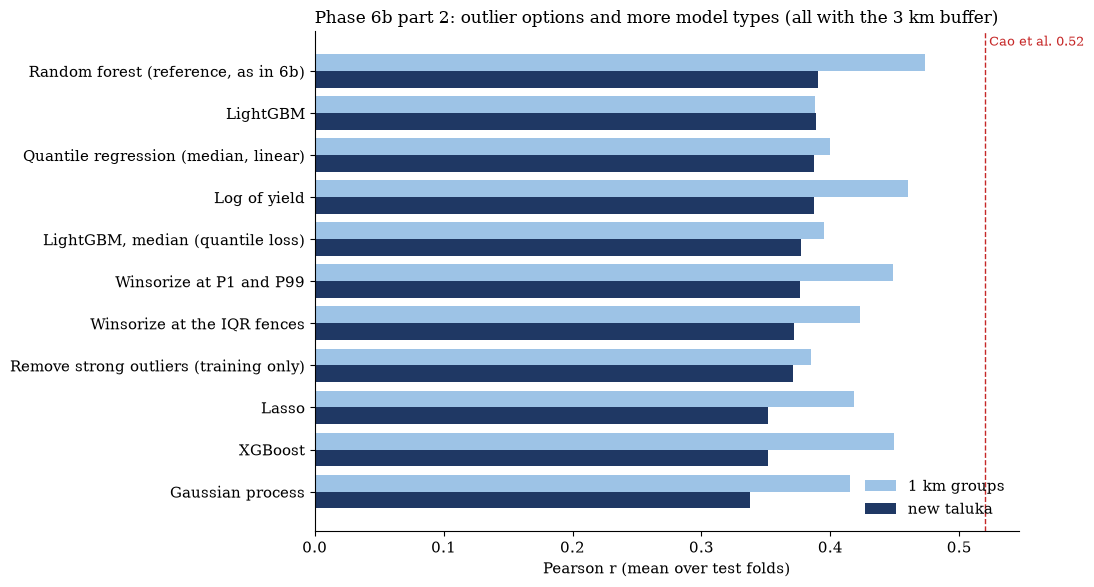

saved: ['P6b2_experiments.csv', 'P6b2_oof_predictions.csv', 'P6b2_paired_tests.csv']


In [6]:
# Step 5: figure, and save the out-of-fold predictions
order = EXP.sort_values("new taluka r", ascending=True)["experiment"]
fig, ax = plt.subplots(figsize=(11, 6)); yy = np.arange(len(order))
for off, col, lab, colr in [(0.2, "1 km groups r", "1 km groups", "#9DC3E6"), (-0.2, "new taluka r", "new taluka", "#1F3864")]:
    v = EXP.set_index("experiment").loc[order, col]; ax.barh(yy + off, v, 0.4, label=lab, color=colr)
ax.set_yticks(yy, order); ax.axvline(0.52, color="#C62828", ls="--", lw=1); ax.text(0.52, len(order) - 0.4, " Cao et al. 0.52", color="#C62828", fontsize=9)
ax.set_xlabel("Pearson r (mean over test folds)"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Phase 6b part 2: outlier options and more model types (all with the 3 km buffer)", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "P6b2_experiments.png", dpi=250, facecolor="white"); plt.show()
pd.concat([oof.assign(experiment=k) for k, (_, _, oof) in RES.items()]).to_csv(OUT / "P6b2_oof_predictions.csv", index=False)
print("saved:", sorted(p.name for p in OUT.glob("P6b2_*")))

## Summary

_(fill after running)_